In [ ]:
import torch
from torch.utils.data import DataLoader

from deep_models.vae import plot_latent_usage
from deep_models.vae_BrainNetCNN import BrainNetCNNVAE
from deep_models.vae_train import *
from deep_models.data import load_folds, make_splits, S00MILDataset

In [7]:
dev_path = "/dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/split_data/one_site/splits/s00_developmental.npz"
split_k = 5

In [8]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
device = torch.device("cuda")

train=1087  val=132  test=134


In [9]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

In [10]:
model = BrainNetCNNVAE(latent=64, cond_dim=0).to(device)  # match your training args
state_dict = torch.load(f"best_vae_bncnn_fold{split_k}.pt", map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()

BrainNetCNNVAE(
  (encoder): Sequential(
    (0): E2EConv(
      (row_conv): Conv2d(5, 32, kernel_size=(1, 17), stride=(1, 1))
      (col_conv): Conv2d(5, 32, kernel_size=(17, 1), stride=(1, 1), bias=False)
    )
    (1): ReLU()
    (2): E2EConv(
      (row_conv): Conv2d(32, 32, kernel_size=(1, 17), stride=(1, 1))
      (col_conv): Conv2d(32, 32, kernel_size=(17, 1), stride=(1, 1), bias=False)
    )
    (3): ReLU()
    (4): DirectedE2N(
      (row_conv): Conv2d(32, 64, kernel_size=(1, 17), stride=(1, 1))
      (col_conv): Conv2d(32, 64, kernel_size=(17, 1), stride=(1, 1), bias=False)
    )
    (5): ReLU()
    (6): Conv2d(64, 256, kernel_size=(17, 1), stride=(1, 1))
    (7): ReLU()
    (8): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (fc): Linear(in_features=64, out_features=256, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(256, 64, kernel_size=(17

In [13]:
val_mu, val_logvar, val_y = encode_bags(model, val_loader, device)

active units: 60/64   total KL: 77.7 nats


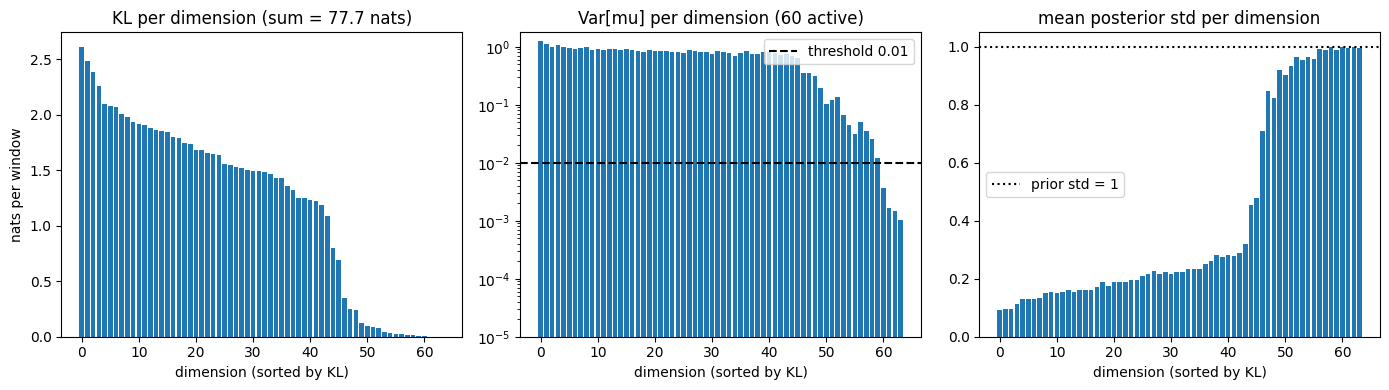

In [ ]:
fig, order, n_active = plot_latent_usage(val_mu, val_logvar, thr=0.01)

# See how well it reconstructs

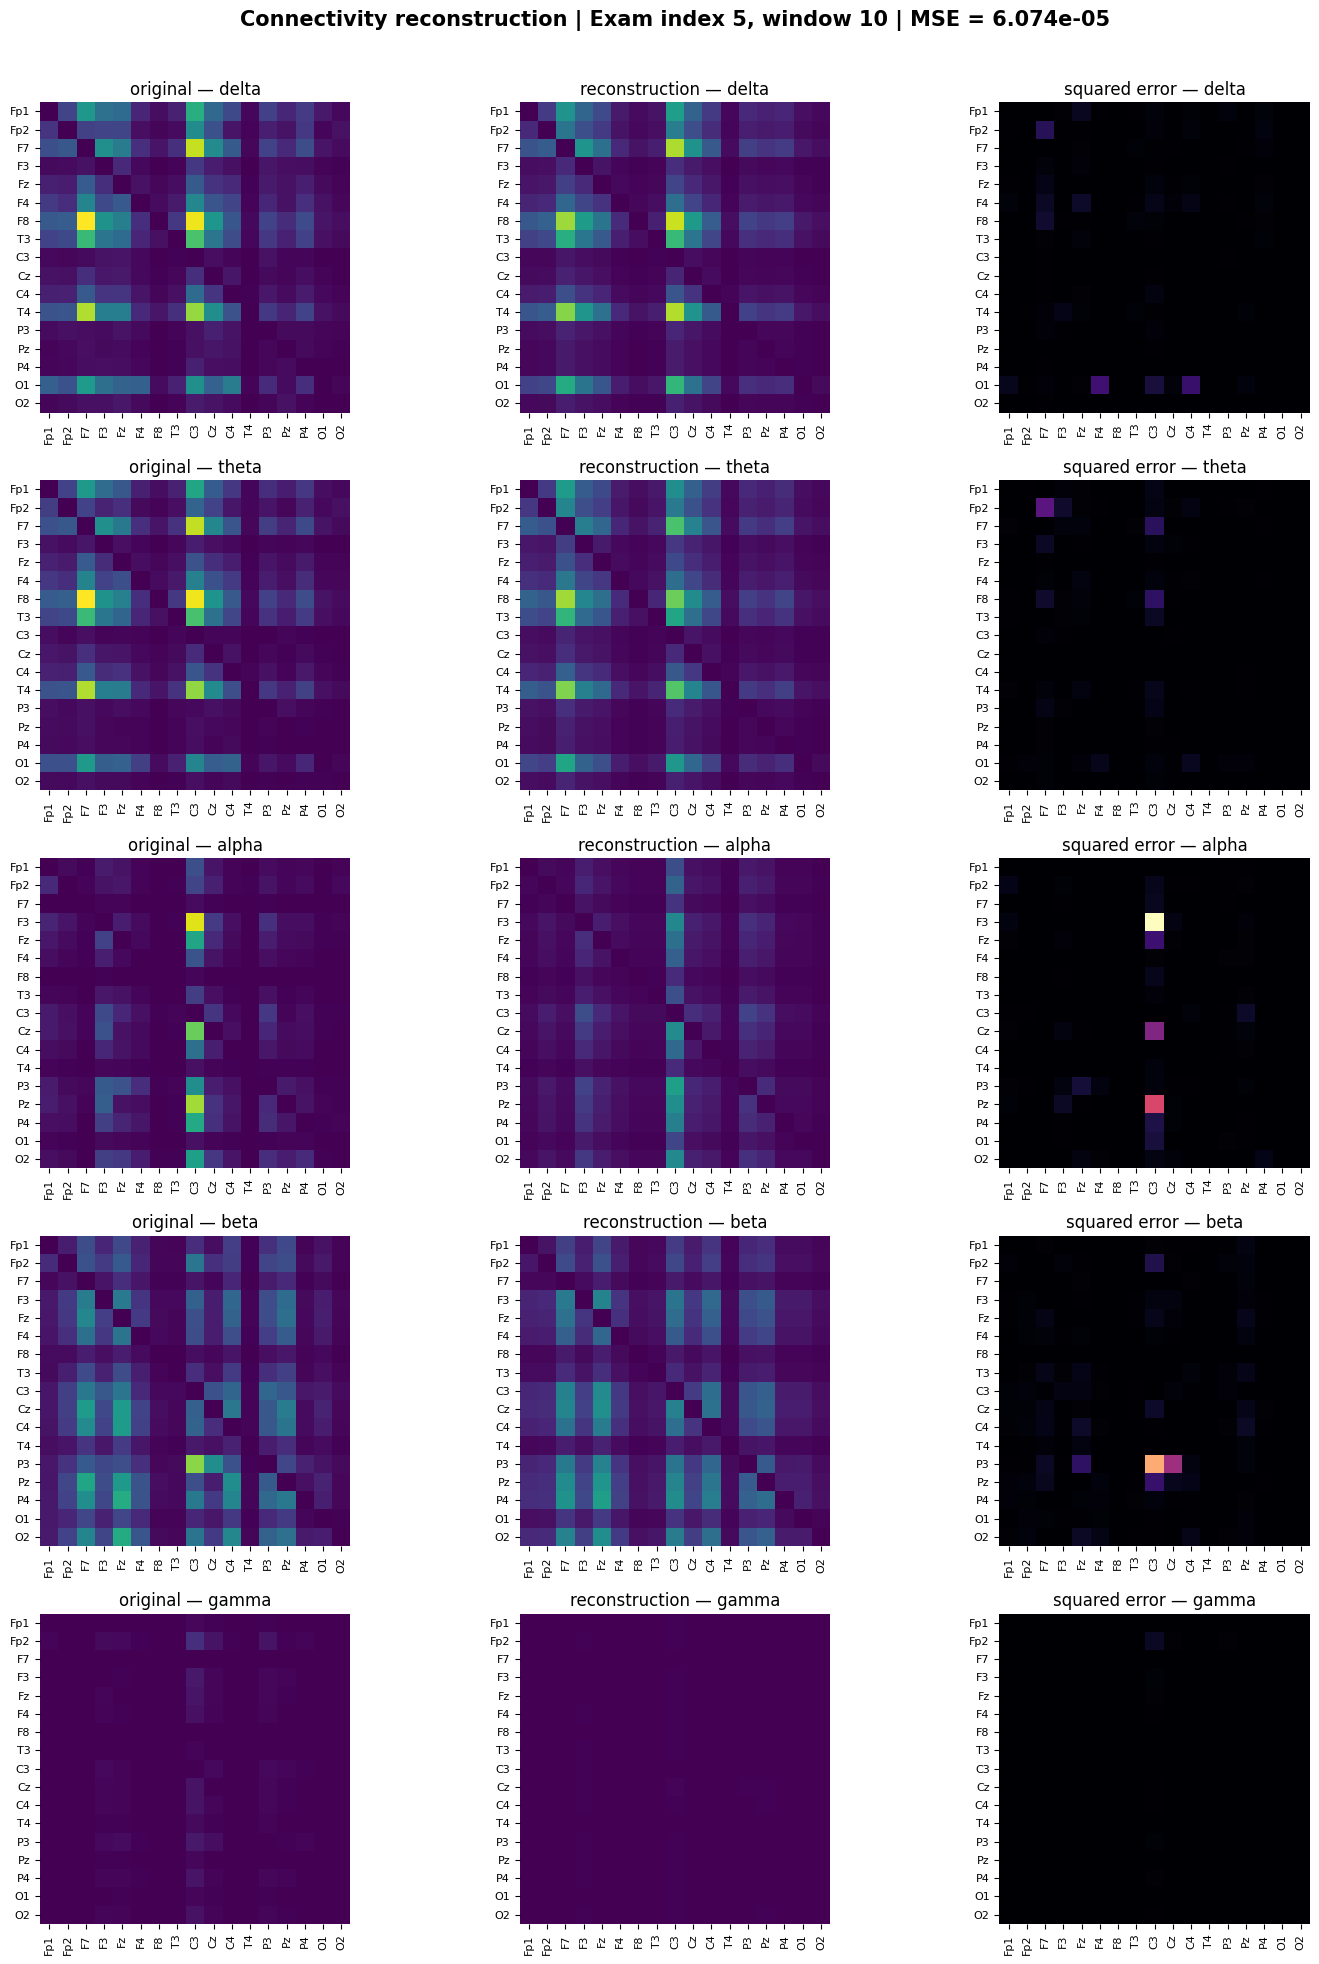

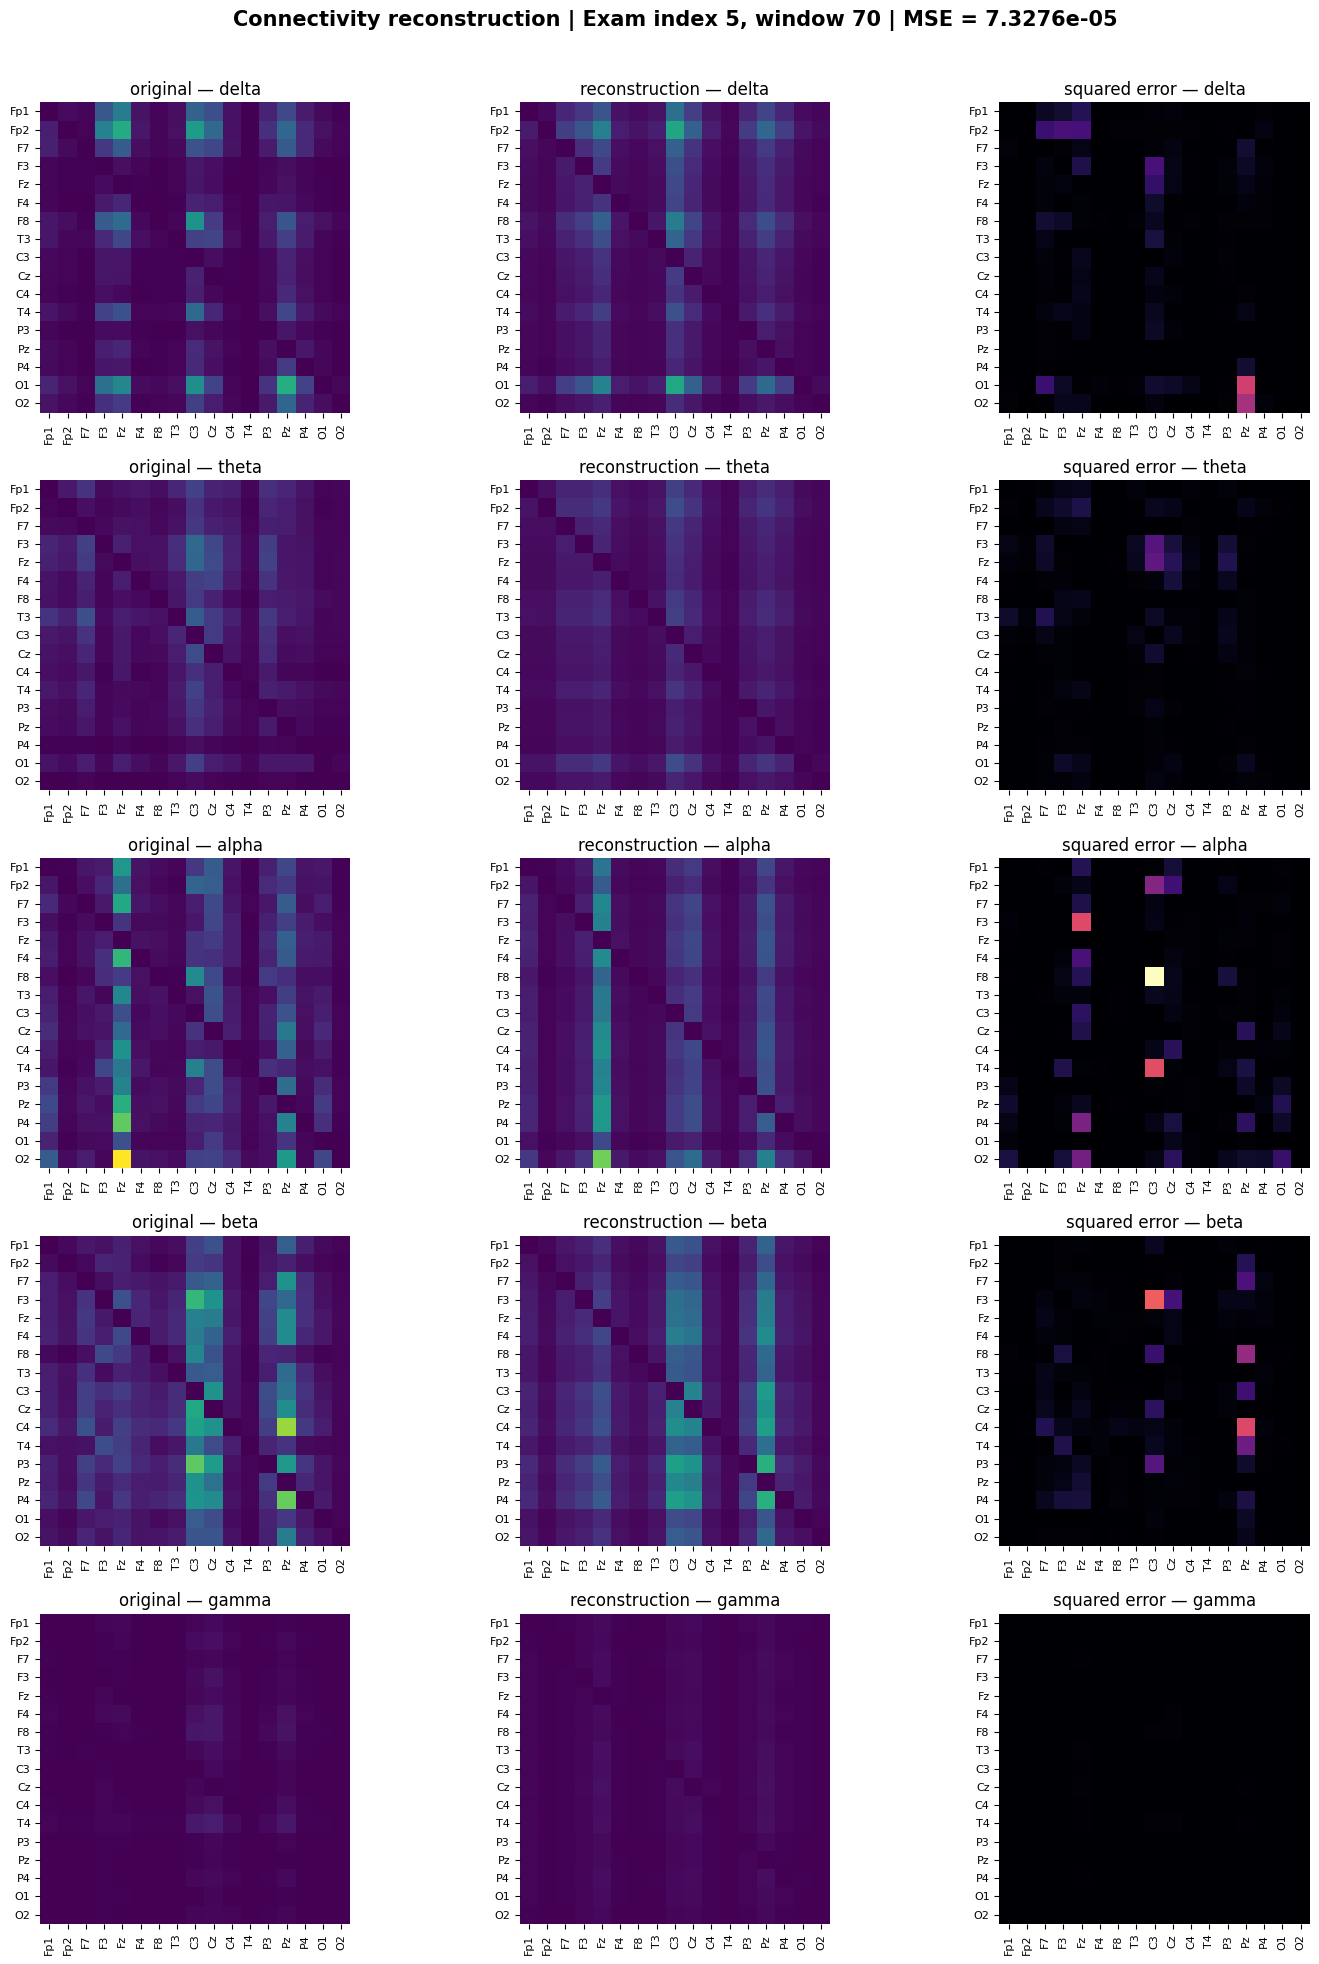

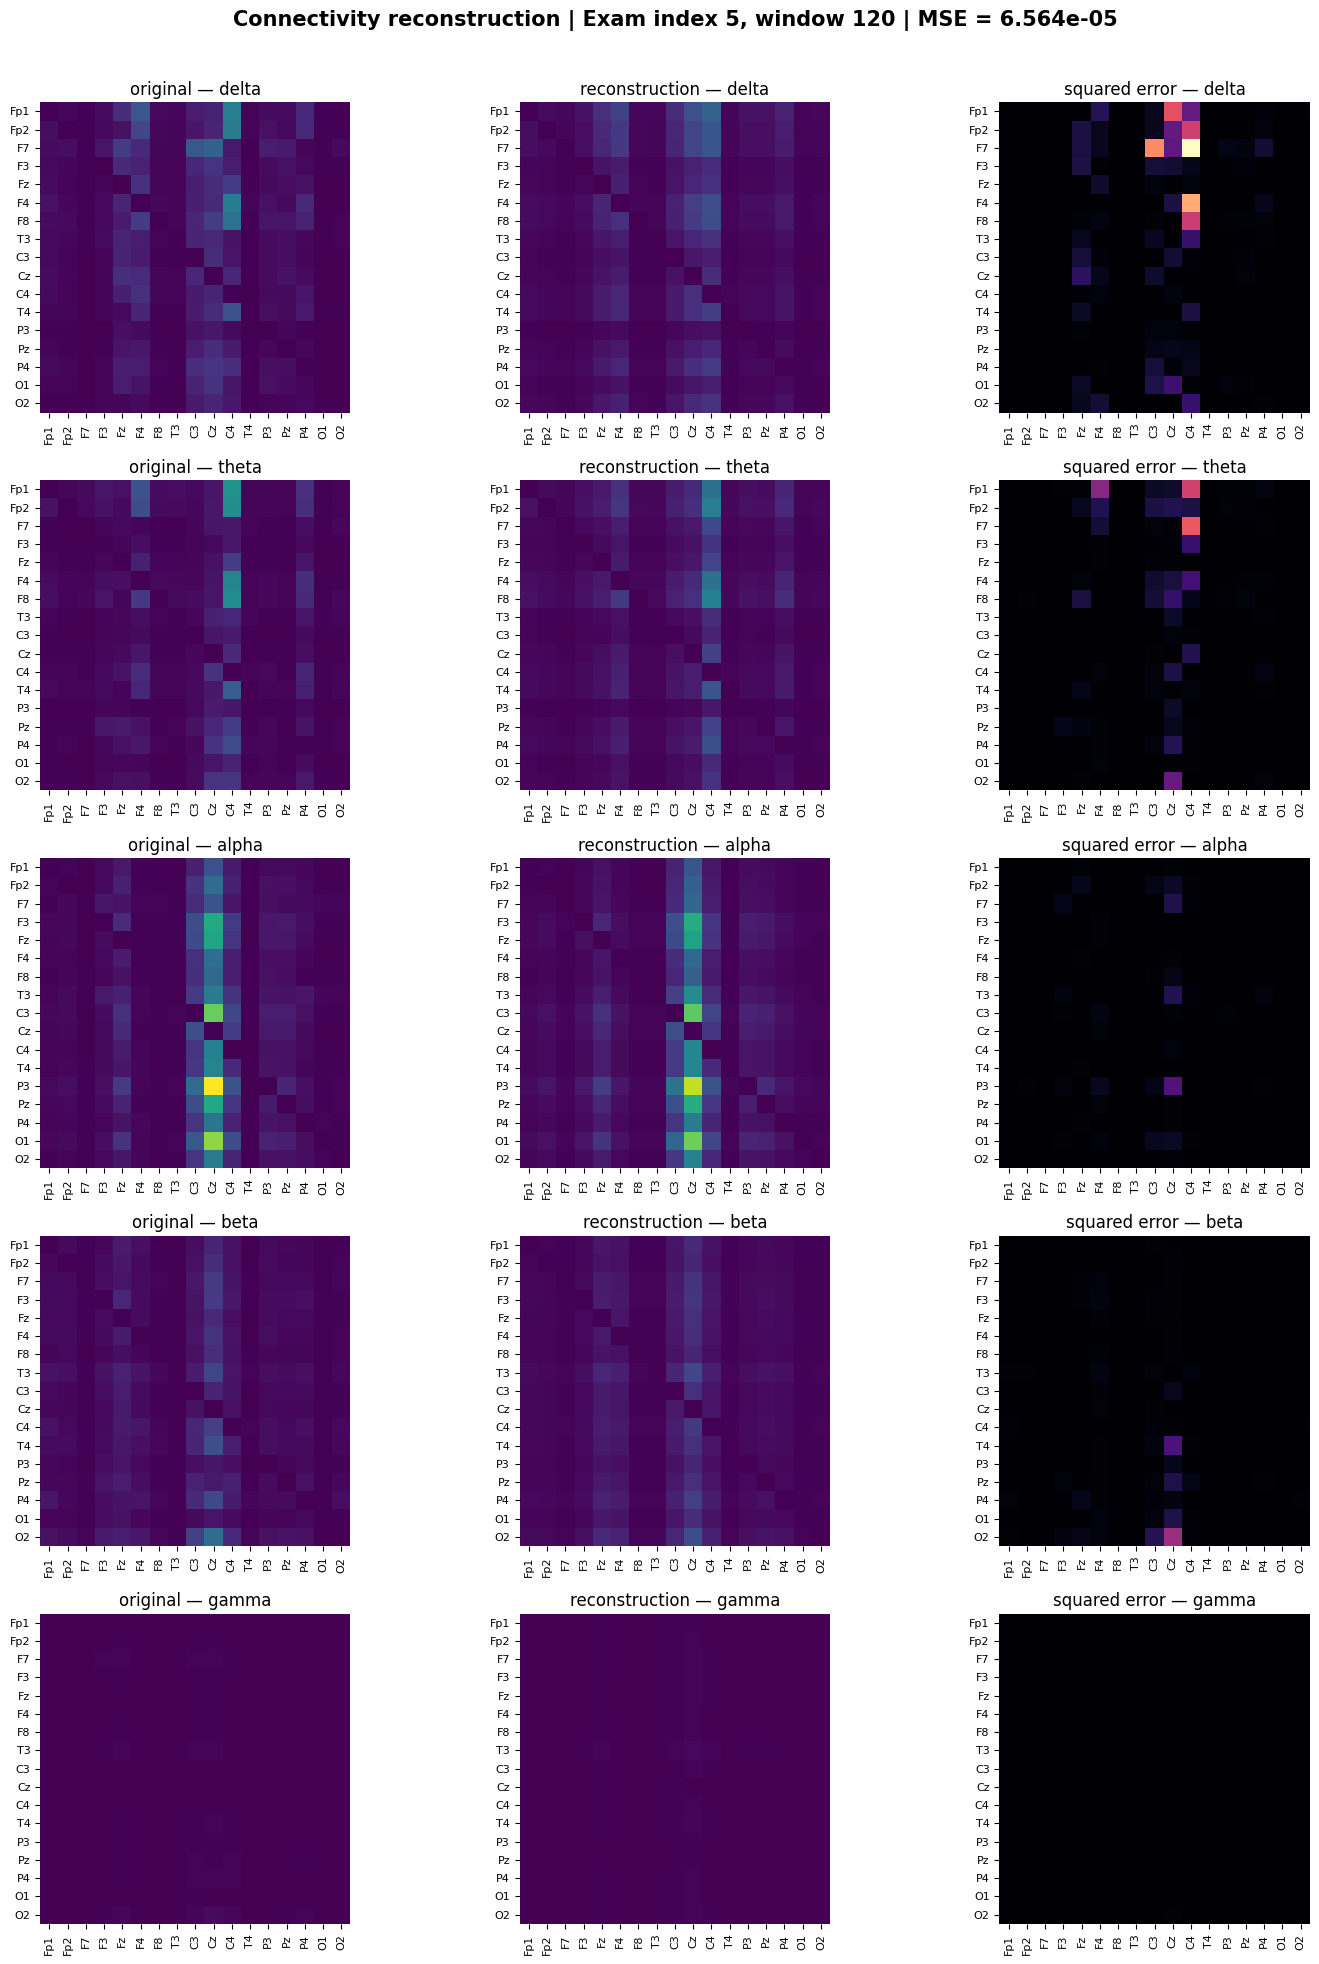

In [16]:
plot_reconstructions(model, val_loader, device, exam_idx=5, window_indices=(10, 70, 120))

# How does the latent space look?

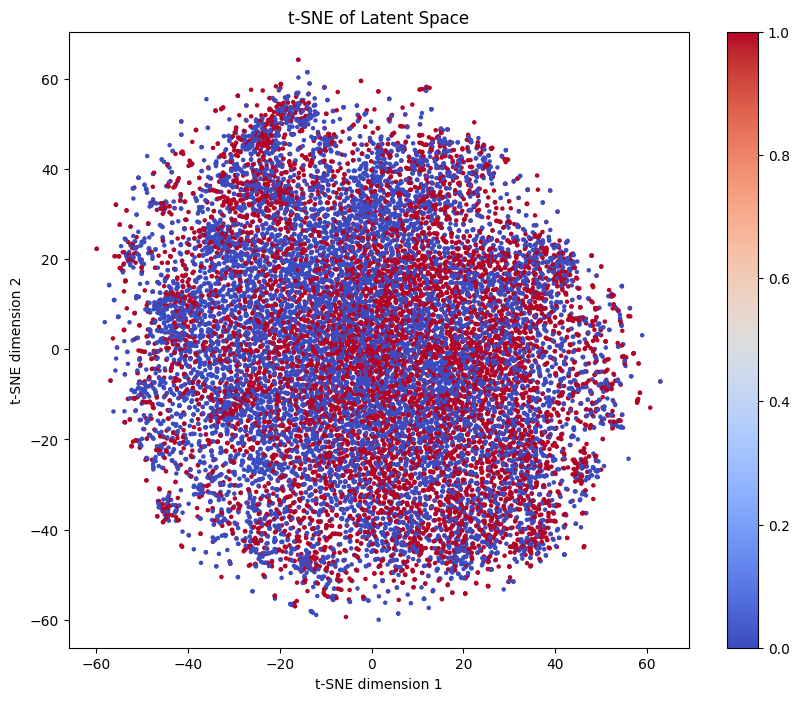

In [17]:
g = plot_tsne(val_mu, val_y)
g.show()

# Test out the generative skill

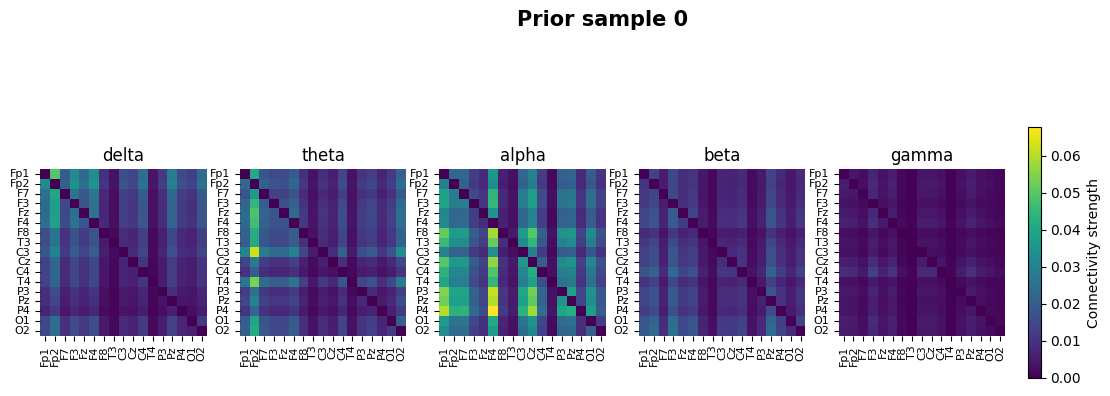

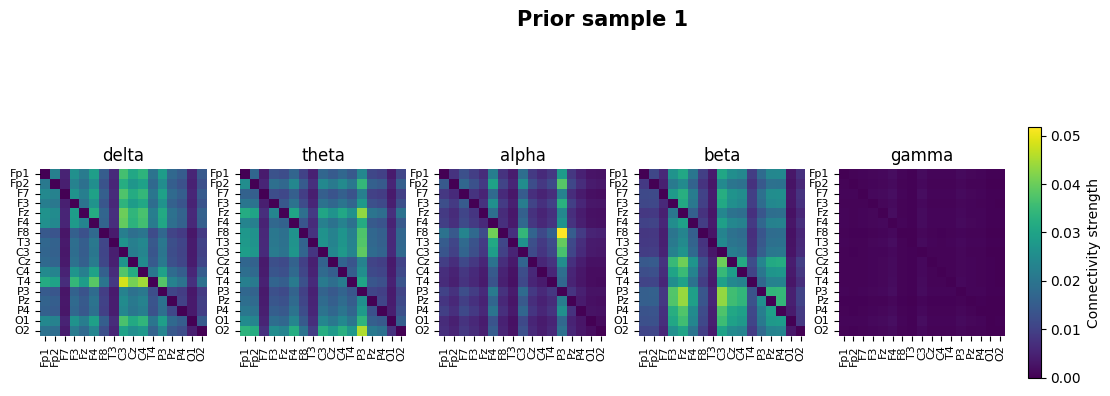

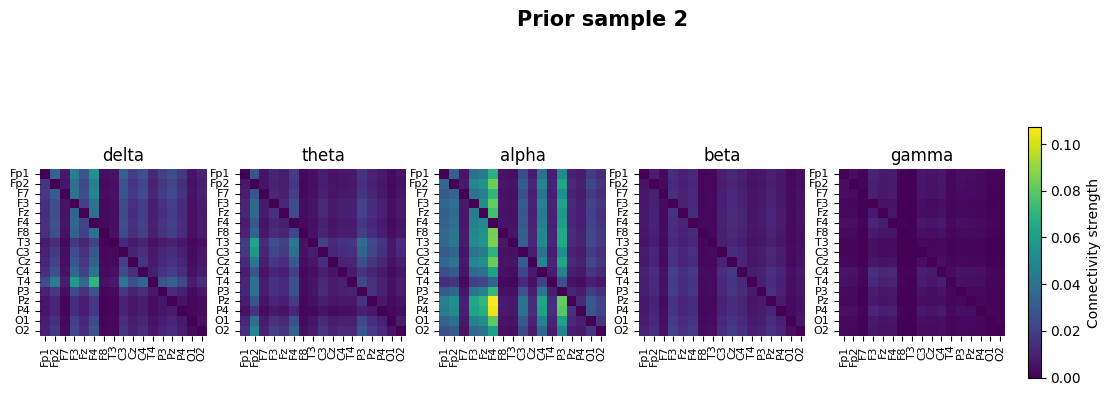

In [18]:
plot_prior_samples(model, device, num_samples=3)